# 02 — Gaussian Naive Bayes: tự viết vs scikit-learn



Giả định các đặc trưng độc lập có điều kiện theo lớp $c$, và mỗi đặc trưng tuân theo phân phối chuẩn:

$$x_j \mid y = c \sim \mathcal{N}(\mu_{cj}, \sigma^2_{cj})$$

$$P(y=c \mid x) \propto P(y=c)\prod_{j=1}^{d}\mathcal{N}(x_j \mid \mu_{cj}, \sigma^2_{cj})$$

$$\log \mathcal{N}(x_j;\mu,\sigma^2) = -\tfrac{1}{2}\left[\log(2\pi\sigma^2) + \frac{(x_j-\mu)^2}{\sigma^2}\right]$$

Tham số được ước lượng bằng MLE: $\hat{\pi}_c = n_c/n$, $\hat{\mu}_{cj}$ là trung bình có điều kiện, $\hat{\sigma}^2_{cj}$ là phương sai có điều kiện (`ddof = 0`).
Cộng thêm một lượng rất nhỏ `var_smoothing` vào phương sai để tránh chia cho 0 khi một đặc trưng có phương sai bằng 0.

## 1. Cài đặt và import

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.naive_bayes import GaussianNB as SklearnGaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)


# Cho phép import package src/ khi chạy notebook từ thư mục notebooks/
from pathlib import Path
import json
import platform
import sklearn

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
from src.models.gaussian import GaussianNB

SEED = 42
np.set_printoptions(precision=6, suppress=True)

print("GaussianNB tự viết  :", GaussianNB)
print("GaussianNB sklearn  :", SklearnGaussianNB)
OUTPUT = ROOT / "results" / "gaussian"
OUTPUT.mkdir(parents=True, exist_ok=True)
def save_table(table, filename):
    table.to_csv(OUTPUT / filename, index=False, encoding="utf-8-sig")
def save_figure(filename):
    plt.gcf().savefig(OUTPUT / filename, dpi=300, bbox_inches="tight")

GaussianNB tự viết  : <class 'src.models.gaussian.GaussianNB'>
GaussianNB sklearn  : <class 'sklearn.naive_bayes.GaussianNB'>


## 2. Nạp dữ liệu MNIST và chia tập

Train gốc: (60000, 784) | Test gốc: (10000, 784)
Khoảng pixel: 0.0 -> 1.0
Nhãn: [0 1 2 3 4 5 6 7 8 9]
Train: (50000, 784) | Val: (10000, 784) | Test: (10000, 784)


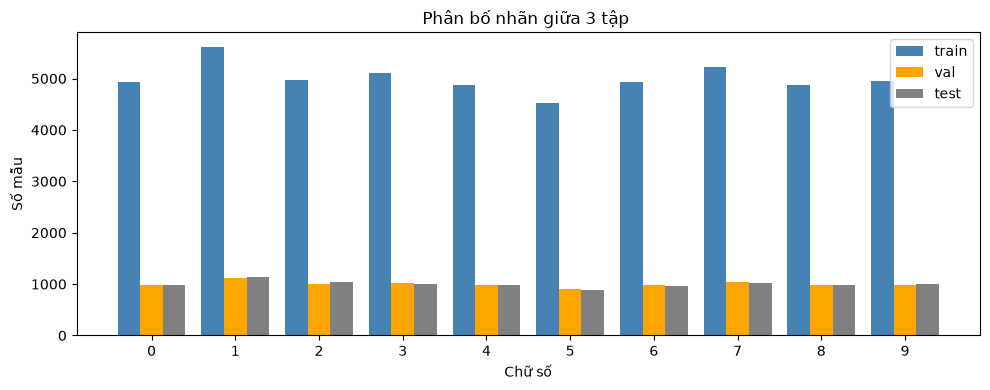

In [2]:
X_train_full, y_train_raw, X_test_full, y_test_all = load_prepared_mnist()

X_all = np.asarray(X_train_full, dtype=np.float32)
y_all = np.asarray(y_train_raw).reshape(-1)
X_test_full = np.asarray(X_test_full, dtype=np.float32)
y_test_all = np.asarray(y_test_all).reshape(-1)

assert X_all.ndim == 2 and X_all.shape[1] == 784
assert X_test_full.ndim == 2 and X_test_full.shape[1] == 784
assert len(X_all) == len(y_all) and len(X_test_full) == len(y_test_all)

print("Train gốc:", X_all.shape, "| Test gốc:", X_test_full.shape)
print("Khoảng pixel:", float(X_all.min()), "->", float(X_all.max()))
print("Nhãn:", np.unique(y_all))


#Chia tập dữ liệu 
tr_idx, va_idx = train_test_split(
    np.arange(len(y_all)), test_size=10000, stratify=y_all, random_state=SEED
)
X_train, X_val = X_all[tr_idx], X_all[va_idx]
y_train, y_val = y_all[tr_idx], y_all[va_idx]
np.savez_compressed(OUTPUT / "split_indices.npz", tr_idx=tr_idx, va_idx=va_idx, seed=SEED)
X_test, y_test = X_test_full, y_test_all

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

# Phân bố nhãn
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(10); w = 0.27
for i, (yv, name, col) in enumerate([
    (y_train, 'train', 'steelblue'),
    (y_val,   'val',   'orange'),
    (y_test,  'test',  'gray')
]):
    counts = np.bincount(yv, minlength=10)
    ax.bar(x + (i-1)*w, counts, w, label=name, color=col)
ax.set_xticks(x); ax.set_xlabel("Chữ số"); ax.set_ylabel("Số mẫu")
ax.set_title("Phân bố nhãn giữa 3 tập ")
ax.legend(); plt.tight_layout(); save_figure("class_distribution.png"); plt.show()

## 3. Hàm đánh giá dùng chung

`predict_in_batches` chia dữ liệu thành từng lô khi dự đoán: cài đặt tự viết tạo mảng trung gian
`(n, k, d) = (n, 10, 784)`, nếu tính một lần cho vài chục nghìn mẫu sẽ tốn vài GB RAM.

In [3]:
def timed_fit(model, X, y):
    """Tính thời gian train model"""
    start = time.perf_counter()
    model.fit(X, y)
    times = time.perf_counter() - start
    return model, times


def predict_in_batches(model, X, batch_size=2048):
    """Dự đoán theo từng lô để tránh cấp phát mảng (n, k, d) quá lớn."""
    parts = [model.predict(X[i : i + batch_size]) for i in range(0, len(X), batch_size)]
    return np.concatenate(parts)


def evaluate_from_pred(name, y_true, y_pred, fit_s=None, predict_s=None):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "fit_seconds": fit_s,
        "predict_seconds": predict_s,
    }

## 4. Huấn luyện Gaussian NB tự viết


- `fit`: với mỗi lớp, tính `priors_` (tỉ lệ lớp), `means_` (trung bình từng điểm ảnh) và `vars_` (phương sai từng điểm ảnh + `var_smoothing`).
- `_log_joint`: tính $\log P(y=c) + \sum_j \log \mathcal{N}(x_j \mid \mu_{cj}, \sigma^2_{cj})$ cho cả $n$ mẫu và $k$ lớp.
- `predict`: lấy lớp có log-joint lớn nhất (tương đương MAP).

In [4]:
manual_gnb = GaussianNB()
manual_gnb, manual_gnb_fit_s = timed_fit(manual_gnb, X_train, y_train)
t = time.perf_counter()
manual_val = predict_in_batches(manual_gnb, X_val)
manual_pred_s = time.perf_counter() - t


manual_val_result = evaluate_from_pred(
    "GaussianNB tự viết", y_val, manual_val, manual_gnb_fit_s, manual_pred_s
)
display(Markdown("**Kết quả trên validation**"))
display(pd.DataFrame([manual_val_result]).round(4))

prior_table = pd.DataFrame(
    {
        "lớp": manual_gnb.classes_,
        "prior (P(y=c))": manual_gnb.priors_,
        "số mẫu train": np.bincount(y_train, minlength=len(manual_gnb.classes_)),
    }
)
display(Markdown("**Xác suất tiên nghiệm học được**"))
display(prior_table.round(5))
print("Shape của means_/vars_ (số lớp, số đặc trưng):", manual_gnb.means_.shape, manual_gnb.vars_.shape)

**Kết quả trên validation**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.5648,0.6828,0.5569,0.5253,0.6379,1.7487


**Xác suất tiên nghiệm học được**

,lớp,prior (P(y=c)),số mẫu train
0,0,0.09872,4936
1,1,0.11236,5618
2,2,0.09930,4965
3,3,0.10218,5109
4,4,0.09736,4868
5,5,0.09036,4518
6,6,0.09864,4932
7,7,0.10442,5221
8,8,0.09752,4876
9,9,0.09914,4957


Shape của means_/vars_ (số lớp, số đặc trưng): (10, 784) (10, 784)


## 5. Huấn luyện Gaussian NB của scikit-learn

Dùng cấu hình mặc định (`var_smoothing = 1e-9`) để so sánh công bằng với cài đặt tự viết.

In [5]:
sk_gnb = SklearnGaussianNB()
sk_gnb, sk_fit_s = timed_fit(sk_gnb, X_train, y_train)
t = time.perf_counter()
sk_val_pred = sk_gnb.predict(X_val)
sk_pred_s = time.perf_counter() - t

sk_val_result = evaluate_from_pred(
    "GaussianNB scikit-learn", y_val, sk_val_pred, sk_fit_s, sk_pred_s
)
display(Markdown("**Kết quả trên validation**"))
display(pd.DataFrame([sk_val_result]).round(4))

**Kết quả trên validation**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB scikit-learn,0.5577,0.6813,0.5498,0.5152,0.2835,0.3731


## 6. So sánh chất lượng và thời gian trên validation

**Bảng tổng hợp (validation)**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.5648,0.6828,0.5569,0.5253,0.6379,1.7487
1,GaussianNB scikit-learn,0.5577,0.6813,0.5498,0.5152,0.2835,0.3731


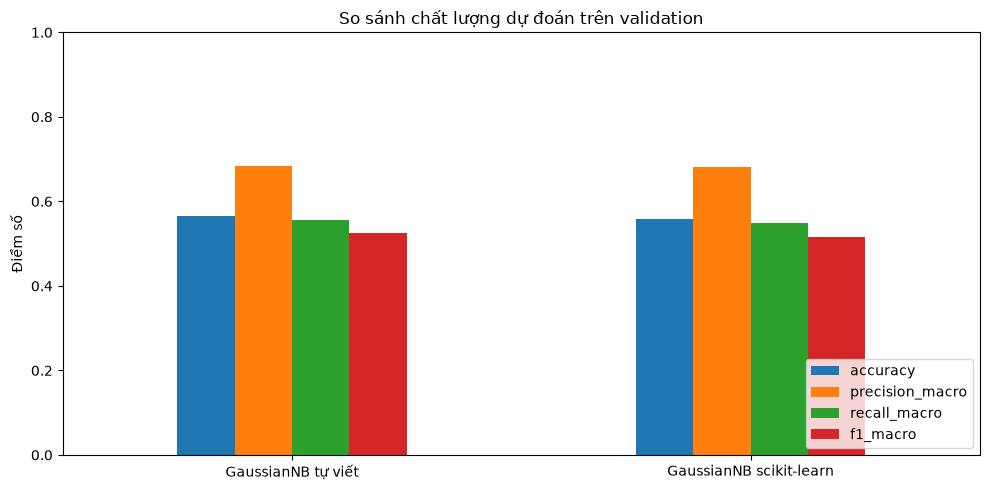

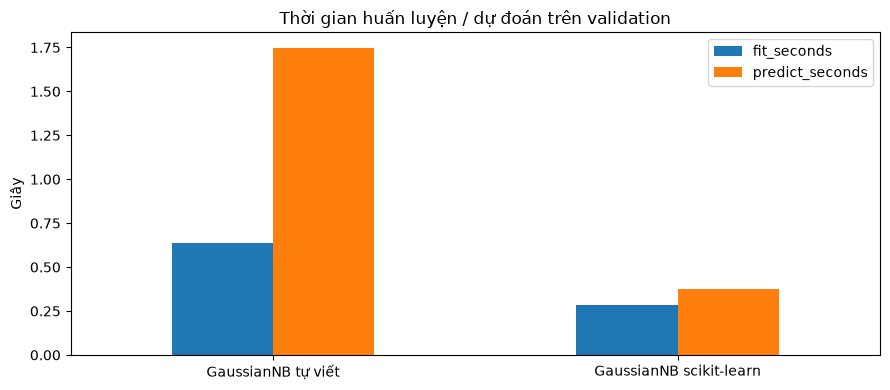

In [6]:
val_results = pd.DataFrame([manual_val_result, sk_val_result])
display(Markdown("**Bảng tổng hợp (validation)**"))
display(val_results.round(4))

metrics_to_plot = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
ax = val_results.set_index("model")[metrics_to_plot].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("So sánh chất lượng dự đoán trên validation")
ax.set_ylabel("Điểm số")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
save_figure("validation_metrics.png"); plt.show()

ax = val_results.set_index("model")[["fit_seconds", "predict_seconds"]].plot(kind="bar", figsize=(9, 4))
ax.set_title("Thời gian huấn luyện / dự đoán trên validation")
ax.set_ylabel("Giây")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
save_figure("validation_times.png"); plt.show()

fit_ratio = sk_fit_s / manual_gnb_fit_s
pred_ratio = sk_pred_s / manual_pred_s


Thời gian fit trên Gaussian sckit-learn nhanh hơn khoảng 2 lần so với Tự viết

Trong khi đó, thời gian predict trên tập val của GaussNB thư viện lại nhanh 
hơn gấp 4 lần so với tự viết (vì thư viện không cấp mảng (n,k,d))

## 7. Kiểm chứng tham số học được

Đây là phần quan trọng nhất để chứng minh cài đặt tự viết **không sai**.

Khi `var_smoothing` được cộng trực tiếp vào phương sai, hai cài đặt dùng chung một tham số nên đặt `var_smoothing = 0` cho cả hai và so sánh trực tiếp:

- `priors_` của tự viết ↔ `class_prior_` của sklearn
- `means_` của tự viết ↔ `theta_` của sklearn
- `vars_` của tự viết ↔ `var_` của sklearn

Dữ liệu được ép về `float64` khi so khớp, vì sklearn giữ nguyên `float32` nếu đầu vào là `float32`.

In [7]:
manual_zero = GaussianNB(var_smoothing=0.0).fit(X_train, y_train)
# sklearn giữ nguyên dtype float32 nếu đầu vào là float32 → ép float64 để so khớp ở độ chính xác cao nhất
sk_zero = SklearnGaussianNB(var_smoothing=0.0).fit(X_train.astype(np.float64), y_train)


def compare(name, a, b):
    a, b = np.asarray(a), np.asarray(b)
    return {
        "đại lượng": name,
        "shape": str(a.shape),
        "sai khác tuyệt đối lớn nhất": float(np.abs(a - b).max()),
        "khớp": bool(np.allclose(a, b, rtol=1e-10, atol=1e-12)),
    }


param_check = pd.DataFrame(
    [
        compare("priors_ / class_prior_", manual_zero.priors_, sk_zero.class_prior_),
        compare("means_ / theta_", manual_zero.means_, sk_zero.theta_),
        compare("vars_ / var_", manual_zero.vars_, sk_zero.var_),
    ]
)
display(Markdown("**So khớp tham số khi `var_smoothing = 0`**"))
display(param_check)
print("classes_ giống nhau:", np.array_equal(manual_zero.classes_, sk_zero.classes_))

print("Ghi chú 1: sklearn dùng epsilon_ = var_smoothing * max_j Var(X_j),")
print("còn cài đặt tự viết cộng thẳng var_smoothing vào từng phương sai.")
print("Vì vậy khi var_smoothing > 0, vars_ của hai bên lệch nhau đúng bằng hiệu số này,")
print("và đó là lý do accuracy của hai mô hình không trùng khít tuyệt đối.")
print("Ghi chú 2: nếu giữ X_train ở float32, sklearn tính trung bình/phương sai bằng float32")
print("nên kết quả lệch cỡ 1e-5 so với bản float64 của cài đặt tự viết.")

**So khớp tham số khi `var_smoothing = 0`**

,đại lượng,shape,sai khác tuyệt đối lớn nhất,khớp
0,priors_ / class_prior_,"(10,)",0.0,True
1,means_ / theta_,"(10, 784)",0.0,True
2,vars_ / var_,"(10, 784)",0.0,True


classes_ giống nhau: True
Ghi chú 1: sklearn dùng epsilon_ = var_smoothing * max_j Var(X_j),
còn cài đặt tự viết cộng thẳng var_smoothing vào từng phương sai.
Vì vậy khi var_smoothing > 0, vars_ của hai bên lệch nhau đúng bằng hiệu số này,
và đó là lý do accuracy của hai mô hình không trùng khít tuyệt đối.
Ghi chú 2: nếu giữ X_train ở float32, sklearn tính trung bình/phương sai bằng float32
nên kết quả lệch cỡ 1e-5 so với bản float64 của cài đặt tự viết.


## 8. So sánh dự đoán và posterior

Với cấu hình mặc định, hai mô hình **không** dùng cùng một epsilon: tự viết cộng thẳng `1e-9` vào phương sai,
còn sklearn dùng `epsilon_ = var_smoothing × max_j Var(X_j)`. Với MNIST `max_j Var(X_j) ≈ 0.2` nên
epsilon của sklearn nhỏ hơn khoảng 5 lần. Do phương sai của nhiều điểm ảnh rất nhỏ, khác biệt này làm
log-joint lệch rất lớn, dù nhãn dự đoán gần như trùng nhau.

Vì vậy ta làm hai bước:

1. Đo mức trùng khớp nhãn dự đoán với cấu hình mặc định.
2. Đặt `var_smoothing` của sklearn bằng `var_smoothing / max_var` để hai bên có **cùng** `var_`,
   rồi kiểm tra log-posterior. Đây mới là phép kiểm chứng cài đặt đúng hay sai.

Posterior được so sánh trên thang log vì xác suất thô gần như bão hoà 0/1 (underflow khi lấy `exp`).

In [8]:
agreement = float(np.mean(manual_val == sk_val_pred))
n_mismatch = int(np.sum(manual_val != sk_val_pred))
print(f"Tỉ lệ dự đoán trùng nhau trên validation (mặc định): {agreement:.4%} ({len(y_val) - n_mismatch}/{len(y_val)} mẫu)")
print("Số mẫu có nhãn dự đoán khác nhau:", n_mismatch)

MAX_VAR = float(np.var(X_train.astype(np.float64), axis=0).max())
print(f"epsilon của sklearn (mặc định) = {float(sk_gnb.epsilon_):.3e}; epsilon của tự viết = 1.000e-09")
print(f"max_j Var(X_j) = {MAX_VAR:.4f}")

sk_proba = sk_gnb.predict_proba(X_val)
saturated = float(np.mean(sk_proba.max(axis=1) > 0.999))
print(f"Tỉ lệ mẫu có xác suất dự đoán > 0.999: {saturated:.2%} → posterior gần như bão hoà 0/1")


def log_posterior_manual(model, X, batch_size=2048):
    """log P(y=c|x) = log-joint - logsumexp(log-joint), tính ổn định theo từng lô."""
    parts = []
    for i in range(0, len(X), batch_size):
        log_joint = model._log_joint(np.asarray(X[i : i + batch_size], dtype=float))
        shift = log_joint.max(axis=1, keepdims=True)
        log_norm = shift + np.log(np.exp(log_joint - shift).sum(axis=1, keepdims=True))
        parts.append(log_joint - log_norm)
    return np.concatenate(parts)


matched_rows = []
for smoothing in [1e-9, 1e-6, 1e-3]:
    m = GaussianNB(var_smoothing=smoothing).fit(X_train, y_train)
    sk = SklearnGaussianNB(var_smoothing=smoothing / MAX_VAR).fit(X_train.astype(np.float64), y_train)
    delta = log_posterior_manual(m, X_val) - sk.predict_log_proba(X_val)
    matched_rows.append(
        {
            "var_smoothing tự viết": f"{smoothing:.0e}",
            "var_smoothing sklearn": f"{smoothing / MAX_VAR:.2e}",
            "sai khác var_ lớn nhất": float(np.abs(m.vars_ - sk.var_).max()),
            "sai khác log-posterior lớn nhất": float(np.abs(delta).max()),
            "tỉ lệ dự đoán trùng": float(np.mean(predict_in_batches(m, X_val) == sk.predict(X_val))),
        }
    )

display(Markdown("**Kiểm chứng với epsilon tương đương**"))
display(pd.DataFrame(matched_rows).round({"sai khác log-posterior lớn nhất": 8}))

Tỉ lệ dự đoán trùng nhau trên validation (mặc định): 98.4700% (9847/10000 mẫu)
Số mẫu có nhãn dự đoán khác nhau: 153
epsilon của sklearn (mặc định) = 1.995e-10; epsilon của tự viết = 1.000e-09
max_j Var(X_j) = 0.1995
Tỉ lệ mẫu có xác suất dự đoán > 0.999: 98.56% → posterior gần như bão hoà 0/1


**Kiểm chứng với epsilon tương đương**

,var_smoothing tự viết,var_smoothing sklearn,sai khác var_ lớn nhất,sai khác log-posterior lớn nhất,tỉ lệ dự đoán trùng
0,1e-09,5.01e-09,0.0,0.000003,1.0
1,1e-06,5.01e-06,0.0,0.000000,1.0
2,1e-03,5.01e-03,0.0,0.000000,1.0


### Ma trận nhầm lẫn và báo cáo theo từng lớp

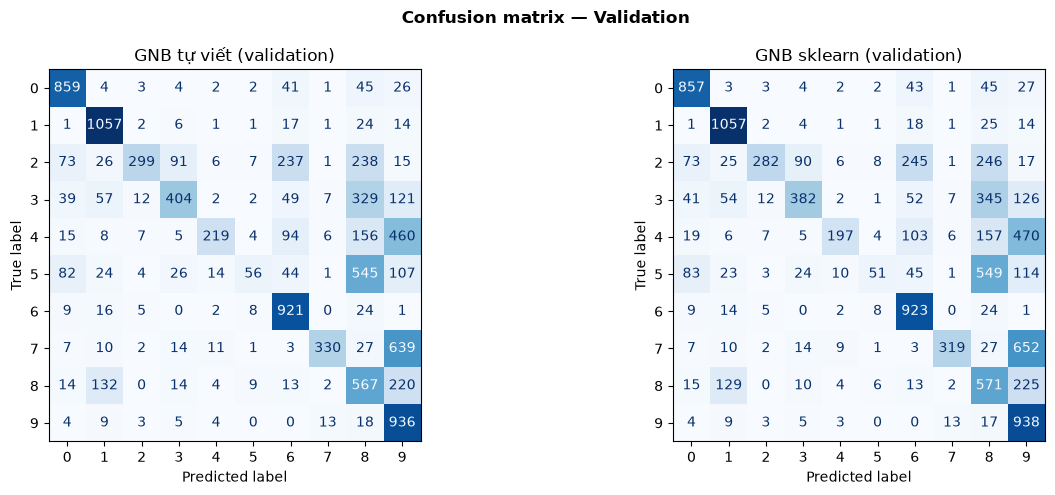

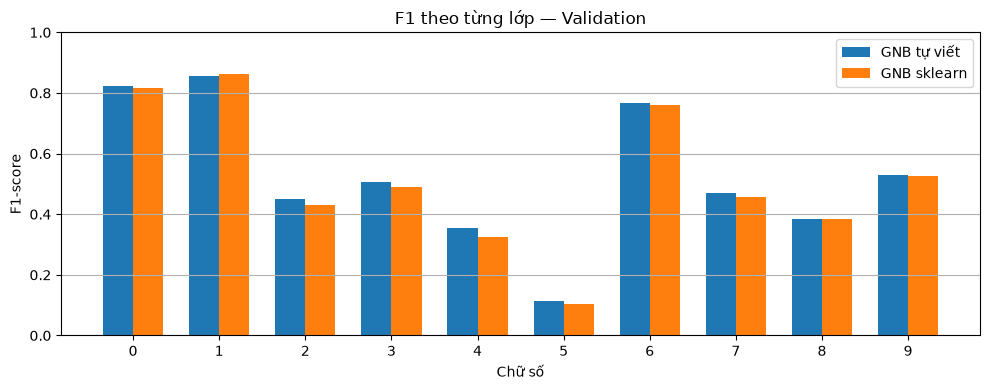

Chênh lệch F1 (manual - sklearn) theo lớp:
  Digit 0: +0.0043
  Digit 1: -0.0045
  Digit 2: +0.0197
  Digit 3: +0.0181
  Digit 4: +0.0279
  Digit 5: +0.0092
  Digit 6: +0.0065
  Digit 7: +0.0121
  Digit 8: +0.0016
  Digit 9: +0.0056


In [9]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val, manual_val, ax=axes[0], cmap='Blues', colorbar=False, values_format='d'
)
axes[0].set_title('GNB tự viết (validation)')

ConfusionMatrixDisplay.from_predictions(
    y_val, sk_val_pred, ax=axes[1], cmap='Blues', colorbar=False, values_format='d'
)
axes[1].set_title('GNB sklearn (validation)')
fig.suptitle('Confusion matrix — Validation', fontweight='bold')
plt.tight_layout(); save_figure("confusion_validation_comparison.png"); plt.show()

# F1 theo từng lớp
f1_manual = f1_score(y_val, manual_val, average=None, zero_division=0)
f1_sk = f1_score(y_val, sk_val_pred, average=None, zero_division=0)

x = np.arange(10); w = 0.35
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - w/2, f1_manual, w, label='GNB tự viết')
ax.bar(x + w/2, f1_sk, w, label='GNB sklearn')
ax.set_xticks(x); ax.set_xlabel('Chữ số'); ax.set_ylabel('F1-score')
ax.set_ylim(0.0, 1.0); ax.set_title('F1 theo từng lớp — Validation')
ax.legend(); plt.grid(axis='y'); plt.tight_layout(); save_figure("f1_per_class_validation.png"); plt.show()

print("Chênh lệch F1 (manual - sklearn) theo lớp:")
for d in range(10):
    print(f"  Digit {d}: {f1_manual[d] - f1_sk[d]:+.4f}")

Hai mô hình dự đoán giống nhau: 98.47%
Cả hai đúng:                   55.65%
Chỉ manual đúng:               0.83%
Chỉ sklearn đúng:              0.12%
Cả hai sai:                    43.40%


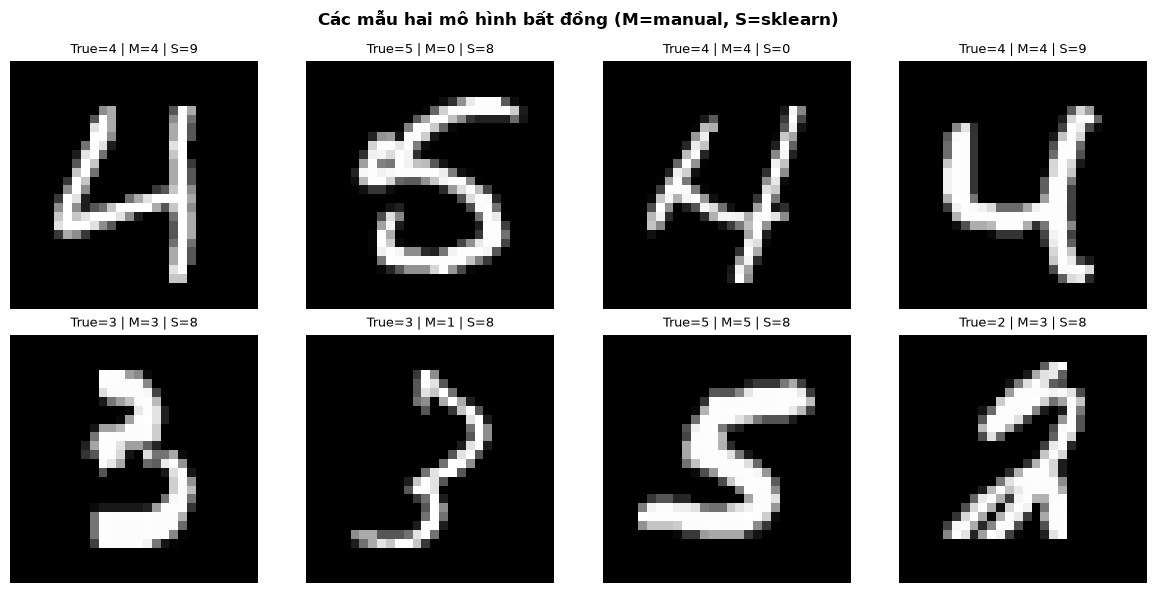

In [10]:
m_right = (manual_val == y_val) #mãng boolean
s_right = (sk_val_pred == y_val)
agree   = (manual_val == sk_val_pred)

print(f"Hai mô hình dự đoán giống nhau: {agree.mean()*100:.2f}%")
print(f"Cả hai đúng:                   {(m_right & s_right).mean()*100:.2f}%")
print(f"Chỉ manual đúng:               {(m_right & ~s_right).mean()*100:.2f}%")
print(f"Chỉ sklearn đúng:              {(~m_right & s_right).mean()*100:.2f}%")
print(f"Cả hai sai:                    {(~m_right & ~s_right).mean()*100:.2f}%")

# Một vài mẫu hai mô hình dự đoán khác nhau
diff_idx = np.where(manual_val != sk_val_pred)[0][:8]
if len(diff_idx) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, idx in zip(axes.ravel(), diff_idx):
        ax.imshow(X_val[idx].reshape(28, 28), cmap='gray')
        ax.set_title(f"True={y_val[idx]} | M={manual_val[idx]} | S={sk_val_pred[idx]}", fontsize=9)
        ax.axis('off')
    fig.suptitle('Các mẫu hai mô hình bất đồng (M=manual, S=sklearn)', fontweight='bold')
    plt.tight_layout(); save_figure("prediction_disagreements.png"); plt.show()

## 9. Ảnh hưởng của `var_smoothing`

`var_smoothing` quá lớn sẽ làm phẳng phân phối của mọi đặc trưng, mô hình mất khả năng phân biệt.
Khảo sát trên validation với cài đặt tự viết (cộng trực tiếp vào phương sai).

Lưu ý: không khảo sát `var_smoothing = 0` vì nhiều điểm ảnh của MNIST luôn bằng 0 (phương sai bằng 0)
sẽ gây chia cho 0 trong công thức mật độ Gauss.

accuracy         f1_macro         precision_macro          \
model          manual sklearn   manual sklearn          manual sklearn   
vs                                                                       
1.000000e-12   0.5313  0.5261   0.4786  0.4712          0.6587  0.6590   
1.000000e-09   0.5648  0.5577   0.5253  0.5152          0.6828  0.6813   
1.000000e-06   0.6279  0.6082   0.6044  0.5797          0.7199  0.7073   
1.000000e-03   0.7635  0.7297   0.7600  0.7229          0.7909  0.7708   
1.000000e-01   0.7594  0.7964   0.7594  0.7952          0.8016  0.8152   
1.000000e+00   0.6594  0.7266   0.6694  0.7290          0.7902  0.7932   

             recall_macro          
model              manual sklearn  
vs                                 
1.000000e-12       0.5232  0.5180  
1.000000e-09       0.5569  0.5498  
1.000000e-06       0.6205  0.6006  
1.000000e-03       0.7587  0.7238  
1.000000e-01       0.7534  0.7925  
1.000000e+00       0.6508  0.7195

var_smoothing tốt nhất trên validation: 0.1 (accuracy=0.7964, F1-macro=0.7952)


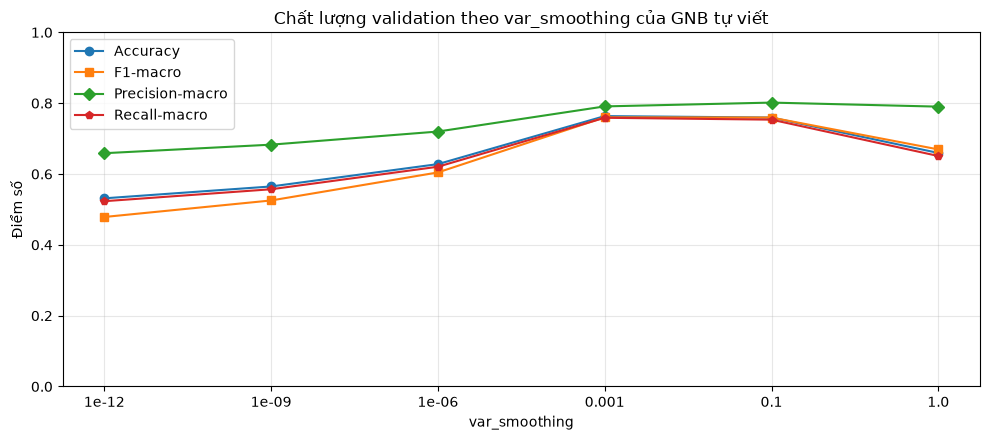

In [11]:
SMOOTHING_VALUES = [1e-12, 1e-9, 1e-6, 1e-3, 1e-1, 1.0]

smoothing_rows = []
for vs in SMOOTHING_VALUES:
    for name in ['manual', 'sklearn']:
        m = (GaussianNB(var_smoothing=vs)
             if name == 'manual'
             else
             SklearnGaussianNB(var_smoothing=vs))
        m, fit_s = timed_fit(m, X_train, y_train)
        t = time.perf_counter()
        pred = predict_in_batches(m, X_val)
        predict_s = time.perf_counter() - t
        r = evaluate_from_pred(name, y_val, pred, fit_s, predict_s)
        r['vs'] = vs
        smoothing_rows.append(r)

sr_df = pd.DataFrame(smoothing_rows)

# Hiển thị bảng so sánh
display(
    sr_df.pivot(
        index="vs",
        columns="model",
        values=["accuracy", "f1_macro", "precision_macro", "recall_macro"],
    ).round(4)
)

best_smoothing = sr_df.loc[sr_df["f1_macro"].idxmax()]
print(
    f"var_smoothing tốt nhất trên validation: {best_smoothing['vs']} "
    f"(accuracy={best_smoothing['accuracy']:.4f}, F1-macro={best_smoothing['f1_macro']:.4f})"
)

positions = np.arange(len(SMOOTHING_VALUES))
fig, ax = plt.subplots(figsize=(10, 4.5))
sub1 = sr_df[sr_df['model'] == 'manual']
ax.plot(positions, sub1["accuracy"], marker="o", label="Accuracy")
ax.plot(positions, sub1["f1_macro"], marker="s", label="F1-macro")
ax.plot(positions, sub1["precision_macro"], marker="D", label="Precision-macro")
ax.plot(positions, sub1["recall_macro"], marker="p", label="Recall-macro")
ax.set_xticks(positions)
ax.set_xticklabels(sub1["vs"])
ax.set_xlabel("var_smoothing")
ax.set_ylabel("Điểm số")
ax.set_ylim(0, 1)
ax.set_title("Chất lượng validation theo var_smoothing của GNB tự viết")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure("smoothing_manual.png"); plt.show()


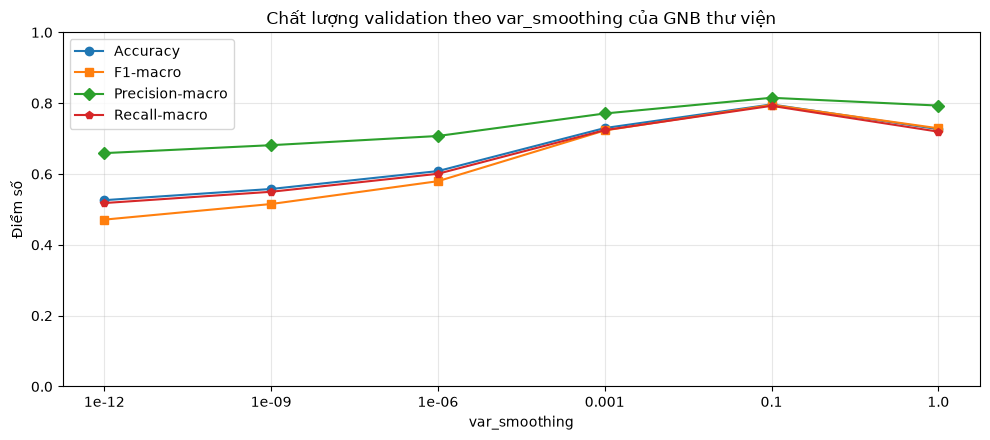

In [12]:
#Đánh giá bằng GaussNB scikit-learn
fig, ax = plt.subplots(figsize=(10, 4.5))
sub2 = sr_df[sr_df['model'] == 'sklearn']
ax.plot(positions, sub2["accuracy"], marker="o", label="Accuracy")
ax.plot(positions, sub2["f1_macro"], marker="s", label="F1-macro")
ax.plot(positions, sub2["precision_macro"], marker="D", label="Precision-macro")
ax.plot(positions, sub2["recall_macro"], marker="p", label="Recall-macro")
ax.set_xticks(positions)
ax.set_xticklabels(sub2["vs"])
ax.set_xlabel("var_smoothing")
ax.set_ylabel("Điểm số")
ax.set_ylim(0, 1)
ax.set_title("Chất lượng validation theo var_smoothing của GNB thư viện")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
save_figure("smoothing_sklearn.png"); plt.show()

## 10. Đánh giá cuối cùng trên tập test

Sử dụng var_smoothing = 1e-3 cho GNB tự viết và var_smoothing = 0.1 cho thư viện 


In [13]:
#Huấn luyện bằng GNB tự viết
start_fit_GNB = time.perf_counter()
manual, fit_s = timed_fit(GaussianNB(var_smoothing=1e-3), X_train, y_train )
time_fit_GNB = time.perf_counter() - start_fit_GNB

train_pred = predict_in_batches(manual, X_train)
print("Accuracy trên tập Train (tự viết):", accuracy_score(y_train, train_pred))

#Huấn luyện bằng GNB thư viện
start_fit_sk = time.perf_counter()
sk, fit_sk_s = timed_fit(SklearnGaussianNB(var_smoothing=0.1), X_train, y_train)
time_fit_sk = time.perf_counter() - start_fit_sk

#pred bằng GNB
start_train_GNB = time.perf_counter()
y_pred = predict_in_batches(manual, X_test)
time_pred_GNB = time.perf_counter() - start_train_GNB

#pred bằng thư viện
start_train_sk = time.perf_counter()
y_pred_sk = sk.predict(X_test)
time_pred_sk = time.perf_counter() - start_train_sk

 
test_results = pd.DataFrame(
    [
        evaluate_from_pred("GaussianNB tự viết", y_test, y_pred, time_fit_GNB, time_pred_GNB),
        evaluate_from_pred("GaussianNB scikit-learn", y_test, y_pred_sk, fit_sk_s, time_pred_sk),
    ]
)
display(Markdown("**Bảng tổng hợp (test)**"))
display(test_results.round(4))

test_agreement = float(np.mean(y_pred == y_pred_sk))
print(f"Tỉ lệ dự đoán trùng nhau trên test: {test_agreement:.4%}")

Accuracy trên tập Train (tự viết): 0.76832


**Bảng tổng hợp (test)**

,model,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,GaussianNB tự viết,0.7753,0.8019,0.7707,0.7716,0.4106,1.1474
1,GaussianNB scikit-learn,0.8147,0.8312,0.8110,0.8131,0.2617,0.3332


Tỉ lệ dự đoán trùng nhau trên test: 89.4400%


## 11. Kết luận

In [14]:
summary = pd.DataFrame(
    {
        "tiêu chí": [
            "Accuracy (validation, mặc định)",
            "F1-macro (validation, mặc định)",
            "Accuracy (test)",
            "F1-macro (test)",
            "Thời gian fit (s)",
            "Thời gian predict test (s)",
            "Tỉ lệ dự đoán trùng sklearn (test)",
        ],
        "giá trị": [
            manual_val_result["accuracy"],
            manual_val_result["f1_macro"],
            test_results.loc[0, "accuracy"],
            test_results.loc[0, "f1_macro"],
            time_fit_GNB,
            time_pred_GNB,
            test_agreement,
        ],
    }
)
display(summary.round(4))
print(
    "Chênh lệch accuracy test giữa tự viết và sklearn: "
    f"{abs(test_results.loc[0, 'accuracy'] - test_results.loc[1, 'accuracy']):.3e}" #lấy giá trị hàng 0 cột accuracy - hàng 1 cột accuracy
)

,tiêu chí,giá trị
0,"Accuracy (validation, mặc định)",0.5648
1,"F1-macro (validation, mặc định)",0.5253
2,Accuracy (test),0.7753
3,F1-macro (test),0.7716
4,Thời gian fit (s),0.4106
5,Thời gian predict test (s),1.1474
6,Tỉ lệ dự đoán trùng sklearn (test),0.8944


Chênh lệch accuracy test giữa tự viết và sklearn: 3.940e-02


**Nhận xét**

- **Đúng về toán học:** `priors_`, `means_` (`theta_`), `vars_` (`var_`) khớp nhau tới sai số số thực; khi hai bên có cùng `var_` (epsilon tương đương) thì nhãn dự đoán trùng 100% và log-posterior chỉ lệch cỡ $10^{-6}$.
- **Chất lượng:** với cấu hình mặc định, hai mô hình cho accuracy/F1 gần như bằng nhau; chênh lệch nhỏ đến từ cách cộng `var_smoothing` khác nhau. GaussianNB xem mỗi điểm ảnh là biến độc lập nên bỏ qua tương quan không gian — đây là lý do độ chính xác thấp hơn MLP, nhưng bù lại mô hình cực nhẹ và chỉ cần một lượt tính trung bình/phương sai để huấn luyện.
- **Chi phí:** `fit` của cả hai tương đương nhau; khác biệt rõ hơn ở `predict`, nơi cài đặt tự viết tạo mảng trung gian `(n, k, d)` nên cần dự đoán theo lô và chậm hơn sklearn khoảng 2–3 lần.
- **`var_smoothing`:** đây là siêu tham số quan trọng nhất của mô hình này. Giá trị mặc định `1e-9` **không** phải là tốt nhất: tăng lên khoảng `1e-3` giúp accuracy tăng đáng kể, nhưng tăng quá lớn (`1.0`) lại làm phẳng phân phối và giảm chất lượng. Lưu ý vì hai thư viện cộng `var_smoothing` theo hai cách khác nhau, cùng một con số không tương đương giữa tự viết và sklearn.

## 12. Lưu kết quả vào `results/gaussian/`
Chạy Run All để lưu hình, bảng, dự đoán và tham số. Các tệp cùng tên được ghi đè khi chạy lại.


In [15]:
tables = {
    "validation_default_metrics.csv": val_results,
    "test_metrics.csv": test_results,
    "priors.csv": prior_table,
    "parameter_check.csv": param_check,
    "matched_epsilon_check.csv": pd.DataFrame(matched_rows),
    "smoothing_search.csv": sr_df,
    "summary.csv": summary,
}
for filename, table in tables.items():
    save_table(table, filename)
np.savez_compressed(OUTPUT / "predictions.npz", y_validation=y_val,
                    manual_validation_default=manual_val, sklearn_validation_default=sk_val_pred,
                    y_test=y_test, manual_test=y_pred, sklearn_test=y_pred_sk)
np.savez_compressed(OUTPUT / "manual_parameters.npz", classes=manual.classes_,
                    priors=manual.priors_, means=manual.means_, variances=manual.vars_)
import joblib
joblib.dump(sk, OUTPUT / "sklearn_model.joblib")
rows = []
for name, model, fit_seconds in [("manual", manual, fit_s), ("sklearn", sk, fit_sk_s)]:
    for split, X, y in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
        t = time.perf_counter()
        pred = predict_in_batches(model, X)
        row = evaluate_from_pred(name, y, pred, fit_seconds, time.perf_counter() - t)
        row["split"] = split
        rows.append(row)
        labels = np.arange(10)
        pd.DataFrame(confusion_matrix(y, pred, labels=labels), index=labels, columns=labels).to_csv(
            OUTPUT / f"confusion_{name}_{split}.csv", index_label="true_label")
        report = classification_report(y, pred, labels=labels, output_dict=True, zero_division=0)
        pd.DataFrame(report).T.to_csv(OUTPUT / f"classification_report_{name}_{split}.csv")
        np.savez_compressed(OUTPUT / f"predictions_{name}_{split}.npz", y_true=y, y_pred=pred)
save_table(pd.DataFrame(rows), "metrics_all_splits.csv")
config = dict(seed=SEED, validation_fraction=0.1, stratified=True,
              n_train=len(y_train), n_validation=len(y_val), n_test=len(y_test),
              input_dtype=str(X_train.dtype), prediction_batch_size=2048,
              smoothing_grid=SMOOTHING_VALUES,
              final_manual_var_smoothing=1e-3, final_sklearn_var_smoothing=0.1,
              final_configuration="Fixed values from original notebook; not selected again here",
              timing_note="metrics_all_splits uses a separate batched prediction pass")
(OUTPUT / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu kết quả vào:", OUTPUT)
for path in sorted(OUTPUT.iterdir()):
    print(" -", path.name)


Đã lưu kết quả vào: d:\mnist\results\gaussian
 - class_distribution.png
 - classification_report_manual_test.csv
 - classification_report_manual_train.csv
 - classification_report_manual_validation.csv
 - classification_report_sklearn_test.csv
 - classification_report_sklearn_train.csv
 - classification_report_sklearn_validation.csv
 - config.json
 - confusion_manual_test.csv
 - confusion_manual_train.csv
 - confusion_manual_validation.csv
 - confusion_sklearn_test.csv
 - confusion_sklearn_train.csv
 - confusion_sklearn_validation.csv
 - confusion_validation_comparison.png
 - f1_per_class_validation.png
 - manual_parameters.npz
 - matched_epsilon_check.csv
 - metrics_all_splits.csv
 - parameter_check.csv
 - prediction_disagreements.png
 - predictions.npz
 - predictions_manual_test.npz
 - predictions_manual_train.npz
 - predictions_manual_validation.npz
 - predictions_sklearn_test.npz
 - predictions_sklearn_train.npz
 - predictions_sklearn_validation.npz
 - priors.csv
 - sklearn_model.j